# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 2. Поиск по образцу.**

## Артемьев М.О. ЕТ-228

Смените рабочую директорию с помощью команды `chdir()`. Для этого передайте этой команде свой путь до каталога, в котором содержатся материалы второй практической работы. После выполнения этой команды все последующие операции с файлами и каталогами будут производиться относительно указанного каталога.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

practice_dir_path = '/content/drive/MyDrive/02 Similarity search'

os.chdir(practice_dir_path)
sys.path.insert(0, practice_dir_path)

print("Рабочая папка:", os.getcwd())
print("Файлы:", os.listdir())

Mounted at /content/drive
Рабочая папка: /content/drive/MyDrive/02 Similarity search
Файлы: ['02 Similarity search.ipynb', 'datasets', 'img', 'modules']


Выполните команды, которые автоматически перезагружают все импортированные модули при их изменении.

In [ ]:
%load_ext autoreload
%autoreload 2

ModuleNotFoundError: No module named 'imp'

Импортируйте библиотеки и модули, необходимые для реализации практической работы 2.

In [ ]:
!pip install mass-ts
!pip uninstall -y sktime
!pip install sktime==0.36.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.0/37.0 MB 73.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 133.6 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: joblib
    Found existing installation: joblib 1.6.0
    Uninstalling joblib-1.6.0:
      Successfully uninstalled joblib-1.6.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [sktime]


In [ ]:
import numpy as np
import pandas as pd
import math
import timeit
import random
import mass_ts as mts
from IPython.display import display

from modules.distance_profile import brute_force
from modules.prediction import *
from modules.bestmatch import *
from modules.utils import *
from modules.plots import *

## **Часть 1.** Поиск по образцу на основе вычисленного профиля расстояния.

**Задача поиска по образцу (subsequence matching)** заключается в нахождении $topK$ наиболее похожих подпоследовательностей временного ряда $T$ длины $n$ на заданный пользователем существенно более короткий временной ряд $Q$ длины $m$, называемый запросом, в смысле некоторой функции расстояния, $m \ll n$. При этом среди найденных подпоследовательностей не должно быть тривиальных совпадений.

Две подпоследовательности $T_{i,m}$ и $T_{j,m}$ временного ряда $T$ являются **тривиальными совпадениями (trivial matches)**, если они пересекаются:
\begin{equation}
|i-j| \leqslant m.
\end{equation}

В общем случае условие пересечения записывается как $|i-j| \leqslant \xi m$, где задаваемый экспертом вещественный параметр $\xi$ $(0 < \xi \leqslant 1)$ имеет типичные значения 0.25, 0.5 или 1.

Одним из вариантов решения данной задачи является вычисление профиля расстояния. Под **профилем расстояния** $DistProfile\in \mathbb{R}^{n-m+1}$ понимается вектор, содержащий расстояния между подпоследовательностями временного ряда $T \in \mathbb{R}^n$ и запросом $Q \in \mathbb{R}^m$, вычисленные с помощью некоторой неотрицательной симметричной функции расстояния $dist(\cdot,\cdot)$:  
\begin{equation}
DistProfile(i) = dist(Q, T_{i,m}), \quad 1 \leqslant i \leqslant n-m+1.
\end{equation}

На основе вычисленного профиля расстояния в качестве $topK$ похожих подпоследовательностей ряда берутся те, которые имеют наименьшие расстояния до запроса:
\begin{equation}
C_{match} = \{T_{i,m}^k\}_{k=1}^{topK},\; где \; T_{i,m}^k \in T, \; i = argsort(DistProfile)(k), \; 1 \leqslant i \leqslant n-m+1.
\end{equation}

В части 1 практической работы 2 вы рассмотрите несколько алгоритмов вычисления профиля расстояния на примере алгоритмов грубой силы и MASS, а также примените результаты их выполнения для решения задачи поиска по образцу. В таблице ниже представлено их тезисное описание.

| <h5> **Алгоритм** </h5> | <h5> **Описание** </h5> | <h5> **Вычислительная <br> сложность** </h5> |
|--------------|------------------------------------------------------------------|:-----------------------------:|
| <p>Brute Force</p>  | <ul><li>Наивный алгоритм</li><li>Z-нормализация запроса и подпоследовательностей ряда по стандартным формулам</li><li>Полное вычисление расстояний между запросом и подпоследовательностями ряда</li></ul> |            <p>$O(mn)$</p>            |
| <p>MASS 1</p>       | <ul><li>Z-нормализация &#171;на лету&#187;</li><li>Применение свертки для вычисления скалярных произведений <br> между запросом и подпоследовательностями ряда</li><li>Выполнение свертки с помощью быстрого преобразования Фурье</li><li>Дополнение справа нулями запроса и временного ряда до удвоенной длины ряда</li><li>Реверс запроса</li></ul> |          <p>$O(n\log{n})$</p>          |
| <p>MASS 2</p>       | <ul><li>MASS 1 – это алгоритм, на котором основан MASS 2</li><li>Вычисление половины свертки</li><li>Дополнение нулями справа только запроса до длины временного ряда</li></ul> |          <p>$O(n\log{n})$</p>          |
| <font size="3">MASS 3</font>       | <ul><li>MASS 2 – это алгоритм, на котором основан MASS 3</li><li>Посегментная обработка временного ряда</li><li>Длина каждого сегмента (кроме, возможно, последнего) – степень двойки</li><li>Сегменты перекрываются на $m-1$ элементов</li></ul> |             <p>$O(\frac{n-k}{k-m}k\log{k})$, <br> где $k$ – длина сегмента </p>           |

### **Задача 1.**

В данном задании вам предстоит определить, имеет ли пациент заболевание сердца по снятой записи ЭКГ или нет. Решать данную задачу будем с помощью алгоритмов поиска по образцу.

Сначала выполните считывание временного ряда и образца поиска из файлов *ECG.csv* и *ECG_query.csv* соответственно из директории *./datasets/part1*. Временной ряд представляет собой показания ЭКГ пациента, образец поиска – фрагмент ЭКГ, обозначающий некоторое кардиологическое заболевание.

In [ ]:
ts_url = './datasets/part1/ECG.csv'
query_url = './datasets/part1/ECG_query.csv'

ts = read_ts(ts_url).reshape(-1)
query = read_ts(query_url).reshape(-1)

/content/drive/MyDrive/02 Similarity search/modules/utils.py:20: FutureWarning:

The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead

/content/drive/MyDrive/02 Similarity search/modules/utils.py:20: FutureWarning:

The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead



Далее выполните визулизацию временного ряда и образца поиска с помощью функции `plot_bestmatch_data()` из модуля *plots.py*.

In [ ]:
plot_bestmatch_data(ts, query)

Реализуйте алгоритм грубой силы (brute force), заполнив одноименную функцию в модуле *distance_profile.py* недостающим кодом. Для этого воспользуйтесь псевдокодом алгоритма, который представлен ниже. После того как вычислен профиль расстояния, найдите $topK$ похожих подпоследовательностей на запрос с помощью функции `topK_match()` из *bestmatch.py*. Для исключения попадания тривиальных совпадений зададим $\xi = 0.5$ Далее параметр $\xi$ будем обозначать в коде как $excl\_zone\_frac$, а величину пересечения как $excl\_zone$, $excl\_zone = \lceil excl\_zone\_frac \cdot m \rceil$,

<center><img src="https://github.com/mzym/TimeSeriesCourse/blob/main/practice/02%20Similarity%20search/img/brute_force.png?raw=true" width="400"></center>

In [ ]:
topK = 2
excl_zone_frac = 0.5
excl_zone = math.ceil(len(query) * excl_zone_frac)
is_normalize = True

naive_bestmatch_results = {}

# INSERT YOUR CODE

dist_profile = brute_force(
    ts,
    query,
    is_normalize=is_normalize
)

naive_bestmatch_results = topK_match(
    dist_profile,
    excl_zone=excl_zone,
    topK=topK
)

print("Результаты поиска:")
print(naive_bestmatch_results)

Результаты поиска:
{'indices': [np.int64(1215), np.int64(193)], 'distances': [np.float64(5.016417971728833), np.float64(18.030850173768773)]}


Напишите функцию `plot_bestmatch_results()` в модуле *plots.py* для визуализации найденных $topK$ похожих подпоследовательностей временного ряда на образец поиска. За основу возьмите функцию `plot_bestmatch_data()` и добавьте отображение найденных подпоследовательностей, выделив их тем же цветом, что и образец поиска.

In [ ]:
plot_bestmatch_results(ts, query, naive_bestmatch_results)

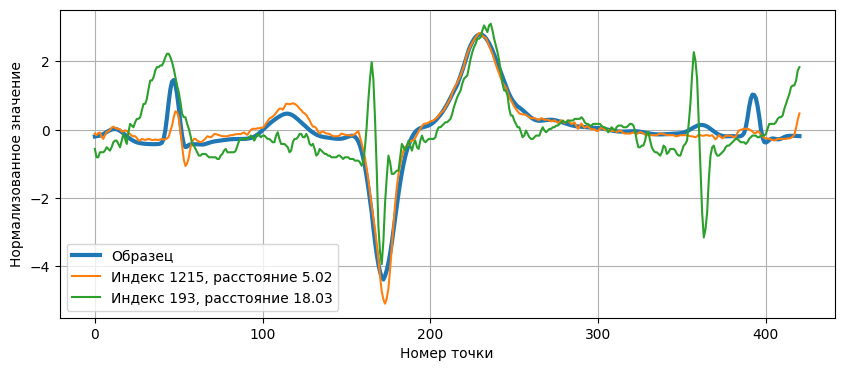

In [ ]:
import matplotlib.pyplot as plt

m = len(query)

plt.figure(figsize=(10, 4))
plt.plot(z_normalize(query), label="Образец", linewidth=3)

for idx, dist in zip(
    naive_bestmatch_results["indices"],
    naive_bestmatch_results["distances"]
):
    fragment = ts[int(idx):int(idx) + m]

    plt.plot(
        z_normalize(fragment),
        label=f"Индекс {idx}, расстояние {dist:.2f}"
    )

plt.xlabel("Номер точки")
plt.ylabel("Нормализованное значение")
plt.legend()
plt.grid()
plt.show()

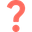
Определите по полученным результатам, имеет ли человек сердечное заболевание или нет.

### Методом Brute Force я нашел два участка ЭКГ, наиболее похожих на заданный образец. Первый участок, с индексом 1215 и расстоянием 5,02, практически повторяет форму образца. Второй, с индексом 193 и расстоянием 18,03, отличается заметно сильнее.

### Поскольку первый участок очень похож на образец заболевания, можно предположить наличие соответствующих изменений ЭКГ у пациента. Однако для подтверждения заболевания одного сходства сигналов недостаточно.

### **Задача 2.**

Проделайте такие же шаги для поиска по образцу, как и в задаче 1, но теперь вычислите профиль расстояния с помощью одной из выбранных вами версий алгоритма MASS. Для этого используйте стороннюю библиотеку *mass-ts*. Со списком всех функций, которые предоставляет данная библиотека, и их описанием вы можете ознакомиться в [репозитории библиотеки GitHub](https://github.com/matrix-profile-foundation/mass-ts).

Обратите внимание, что MASS 2 и MASS 3 возвращают профиль расстояния в виде вектора комплексных чисел. Для дальнейшей работы с профилем расстояния используйте только вещественные части комплексных чисел.     

In [ ]:
# Параметры поиска
topK = 2
excl_zone_frac = 0.5
excl_zone = math.ceil(len(query) * excl_zone_frac)

# профиль расстояний
mass_dist_profile = mts.mass2(ts, query)

# вещественная часть
mass_dist_profile = np.real(mass_dist_profile)

# два лучших совпадения
mass_bestmatch_results = topK_match(
    mass_dist_profile,
    excl_zone=excl_zone,
    topK=topK
)

print("Результаты MASS 2:")
print(mass_bestmatch_results)

# Визуализируем найденные участки
plot_bestmatch_results(
    ts,
    query,
    mass_bestmatch_results
)

Результаты MASS 2:
{'indices': [np.int64(1215), np.int64(193)], 'distances': [np.float64(5.016417971728845), np.float64(18.030850173768773)]}


### Я использовал алгоритм MASS 2 для поиска похожих участков ЭКГ. Он нашел те же два участка, что и Brute Force, с индексами 1215 и 193 и расстояниями 5,02 и 18,03.Таким образом, результаты двух алгоритмов совпали

### **Задача 3.**

Проведите две серии экспериментов по сравнению быстродействия алгоритмов грубой силы и трех версий MASS:
1. на фиксированной длине запроса $m$ при изменяемой длине временного ряда $n$;
2. на фиксированной длине временного ряда $n$ при изменяемой длине запроса $m$.

Все необходимые для проведения экспериментов функции находятся в модуле *experiments.py*.

Сначала сгенерируйте по аналогии временные ряды и запросы поиска различных длин, как это было сделано в практической работе 1. Далее измерьте время выполнения алгоритмов при заданных входных параметрах и данных с помощью функции `run_experiment()`. Полученные результаты (время выполнения) каждого эксперимента отобразите на линейном графике, воспользовавшись функцией `visualize_plot_times()`.

Также вычислите ускорение с помощью функции `calculate_speedup()`, показывающее, во сколько раз алгоритм MASS превосходит по времени выполнения алгоритма грубой силы, по следующей формуле:
\begin{equation}
speedup = \frac{t_{BF}}{t_{MASS}},
\end{equation}
где $t_{BF}$ и $t_{MASS}$ — время работы алгоритма грубой силы и MASS соответственно.

Полученные ускорения оформите в виде таблицы, для построения используйте функцию `visualize_table_speedup()`.

Эксперимент 1

In [ ]:
from modules.experiments import (
    run_experiment,
    visualize_plot_times,
    calculate_speedup,
    visualize_table_speedup
)

algorithms = ['brute_force', 'mass', 'mass2', 'mass3']
algorithms_params = {
    'brute_force': None,
    'mass': None,
    'mass2': None,
    'mass3': {'segment_len': 2048},
}

n_list = [2**15, 2**16, 2**17, 2**18, 2**19, 2**20] # lengths of time series
m = 128 # length of query

exp1_params = {
    'varying': {'n': n_list},
    'fixed': {'m': m}
}

exp1_data = {
    'ts': dict.fromkeys(map(str, n_list), []),
    'query': {str(m): []}
}

task = 'distance_profile'

# generate set of time series and query
# run experiments for measurement of algorithm runtimes

# INSERT YOUR CODE

random.seed(2027)

for n in n_list:
    exp1_data['ts'][str(n)] = random_walk(n)

exp1_data['query'][str(m)] = random_walk(m)

exp1_times = []

for algorithm in algorithms:
    times = run_experiment(
        algorithm=algorithm,
        task=task,
        data=exp1_data,
        exp_params=exp1_params,
        alg_params=algorithms_params[algorithm]
    )

    exp1_times.append(times)

exp1_times = np.array(exp1_times)

print("Размер массива с результатами:", exp1_times.shape)
print(exp1_times)

Размер массива с результатами: (4, 6)
[[6.10446952e+00 4.43584634e+00 9.09913198e+00 1.75491109e+01
  3.42003497e+01 6.88793557e+01]
 [1.37533330e-02 2.68818800e-02 6.40589410e-02 1.60313689e-01
  3.69466036e-01 5.97905789e-01]
 [3.46842830e-02 6.50908900e-02 1.32098892e-01 2.76554100e-01
  5.83569049e-01 1.14337448e+00]
 [3.73182500e-02 6.66722880e-02 1.35983732e-01 3.03078881e-01
  6.24950755e-01 1.59394835e+00]]


In [ ]:
# visualize plot with results of experiment
comparison_param = np.array(algorithms)

# INSERT YOUR CODE

visualize_plot_times(
    exp1_times,
    comparison_param,
    exp1_params
)

In [ ]:
# visualize table with speedup
tab_index = algorithms[1:]
tab_columns = [f"n = {n}" for n in n_list]
tab_title = "Speedup MASS relative to the brute force <br> (variable time series length, fixed query length)"

# INSERT YOUR CODE

speedup_exp1 = calculate_speedup(
    exp1_times[0],
    exp1_times[1:]
)

visualize_table_speedup(
    speedup_exp1,
    tab_index,
    tab_columns,
    tab_title
)

,n = 32768,n = 65536,n = 131072,n = 262144,n = 524288,n = 1048576
mass,443.853829,165.012505,142.043122,109.467326,92.566965,115.201018
mass2,176.001029,68.148497,68.881213,63.456340,58.605489,60.242166
mass3,163.578665,66.532085,66.913386,57.902784,54.724871,43.213041


Эксперимент 2

In [ ]:
m_list = [2**5, 2**6, 2**7, 2**8, 2**9, 2**10] # lengths of queries
n = 2**15 # length of time series

exp2_params = {
    'varying': {'m': m_list},
    'fixed': {'n': n}
}

exp2_data = {
    'ts': {str(n): []},
    'query': dict.fromkeys(map(str, m_list), [])
}

# INSERT YOUR CODE

exp2_data['ts'][str(n)] = random_walk(n)

for m in m_list:
    exp2_data['query'][str(m)] = random_walk(m)

exp2_times = []

for algorithm in algorithms:
    print("Выполняется:", algorithm, flush=True)

    times = run_experiment(
        algorithm=algorithm,
        task=task,
        data=exp2_data,
        exp_params=exp2_params,
        alg_params=algorithms_params[algorithm]
    )

    exp2_times.append(times)

exp2_times = np.array(exp2_times)

print("Размер массива:", exp2_times.shape)
print(exp2_times)

Выполняется: brute_force
Выполняется: mass
Выполняется: mass2
Выполняется: mass3
Размер массива: (4, 6)
[[1.64820857 1.71386463 2.43125388 3.16293026 2.28090757 2.16118965]
 [0.01432775 0.01264466 0.01242495 0.00938207 0.00845589 0.00821907]
 [0.01341328 0.01993313 0.03180241 0.05785377 0.10486921 0.20271939]
 [0.01427548 0.01754153 0.02935681 0.06006959 0.10572277 0.19998187]]


In [ ]:
comparison_param = np.array(algorithms)

visualize_plot_times(
    exp2_times,
    comparison_param,
    exp2_params
)

In [ ]:
tab_index = algorithms[1:]
tab_columns = [f"m = {m}" for m in m_list]
tab_title = "Speedup MASS relative to the brute force <br> (variable query length, fixed time series length)"

# INSERT YOUR CODE

speedup_exp2 = calculate_speedup(
    exp2_times[0],
    exp2_times[1:]
)

visualize_table_speedup(
    speedup_exp2,
    tab_index,
    tab_columns,
    tab_title
)

,m = 32,m = 64,m = 128,m = 256,m = 512,m = 1024
mass,115.036090,135.540554,195.675160,337.124847,269.741772,262.948135
mass2,122.878843,85.980721,76.448724,54.671122,21.750021,10.660991
mass3,115.457297,97.703252,82.817367,52.654437,21.574420,10.806928


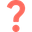
Проанализируйте и изложите содержательный смысл полученных
результатов.

### В третьей задаче я сравнил скорость Brute Force и трех версий MASS в двух экспериментах.

### В первом эксперименте я увеличивал длину временного ряда, оставляя длину запроса неизменной. Время работы Brute Force выросло с 1,9 до 71 секунды, тогда как все версии MASS работали значительно быстрее. Самым быстрым оказался MASS 1, который обеспечил ускорение примерно в 140–305 раз.

### Во втором эксперименте я зафиксировал длину временного ряда и увеличивал длину запроса. MASS 1 сохранял практически постоянное время работы около 0,01 секунды. MASS 2 и MASS 3 постепенно замедлялись, но всё равно оставались быстрее Brute Force.

### Все три версии MASS показали преимущество перед полным перебором. В моих экспериментах самым быстрым оказался MASS 1. Особенно заметно преимущество MASS при работе с длинными временными рядами.

## **Часть 2.** Ускорение вычисления DTW меры техникой ограничения полосы Сако—Чиба. Наивный алгоритм поиска по образцу на основе DTW меры.

### **Задача 4.**

Поскольку DTW мера имеет квадратичную вычислительную сложность от
длины временного ряда $O(n^2)$, то в данном задании вам предстоит реализовать технику ограничения полосы Сако–Чиба. Данная техника не позволяет отклоняться пути трансформации более чем на $r$ ячеек от диагонали матрицы трансформации и тем самым сокращает вычисление меры до $O(rn)$.

Добавьте в функцию `DTW_distance()` из модуля *metrics.py* возможность ограничения полосы Сако—Чиба. Сравните результаты выполнения вашей реализации с результатами функции [`dtw_distance()`](https://www.sktime.net/en/stable/api_reference/auto_generated/sktime.distances.dtw_distance.html) из библиотеки *sktime*, задав различные значения параметра $r$ (например, от 0 до 1 с шагом 0.05).

**Мера DTW с ограничением полосы Сако–Чиба** вычисляется следующим образом:
\begin{equation}
\text{DTW}(T_1, T_2) = d(n,n),
\\ d(i,j) = (t_{1,i} - t_{2,j})^2 + \min \left\{
	\begin{array}{l l}
	d(i-1,j), \\
	d(i,j-1), \\
	d(i-1,j-1),
	\end{array}
	\right.
\\ d(0,0)=0, \quad d(i,0)=d(0,j)=\infty, \quad  1 \leqslant i,j \leqslant n;
\\ 0 \leqslant r \leqslant n-1, \quad j-r \leqslant i \leqslant j+r,
\\ d(i,j) = \infty, \quad j+r < i < j-r.
\end{equation}

In [ ]:
def test_distances(dist1: float, dist2: float) -> None:
    """
    Check whether your distance function is implemented correctly

    Parameters
    ----------
    dist1 : distance between two time series calculated by sktime
    dist2 : distance between two time series calculated by your function
    """

    np.testing.assert_equal(round(dist1, 5), round(dist2, 5), 'Distances are not equal')

In [ ]:
import importlib
import numpy as np
import modules.metrics
from sktime.distances import dtw_distance
importlib.reload(modules.metrics)
from modules.metrics import DTW_distance

# Создаем два ряда одинаковой длины
rng = np.random.default_rng(2027)

ts1 = rng.uniform(0, 10, size=100)
ts2 = rng.uniform(0, 10, size=100)

# Проверяем r от 0 до 1 включительно с шагом 0.05
r_values = np.round(np.linspace(0, 1, 21), 2)

print(f"{'r':>5} | {'sktime':>14} | {'Моя функция':>14} | Проверка")
print("-" * 60)

for r in r_values:
    r = float(r)

    dist_sktime = dtw_distance(ts1, ts2, window=r)
    dist_my = DTW_distance(ts1, ts2, r=r)

    test_distances(dist_sktime, dist_my)

    print(
        f"{r:5.2f} | {dist_sktime:14.5f} | "
        f"{dist_my:14.5f} | Совпало"
    )

print("\nВсе проверки пройдены!")

    r |         sktime |    Моя функция | Проверка
------------------------------------------------------------
 0.00 |     1581.61944 |     1581.61944 | Совпало
 0.05 |      335.10285 |      335.10285 | Совпало
 0.10 |      293.34016 |      293.34016 | Совпало
 0.15 |      293.34016 |      293.34016 | Совпало
 0.20 |      293.34016 |      293.34016 | Совпало
 0.25 |      293.34016 |      293.34016 | Совпало
 0.30 |      293.34016 |      293.34016 | Совпало
 0.35 |      293.34016 |      293.34016 | Совпало
 0.40 |      293.34016 |      293.34016 | Совпало
 0.45 |      293.34016 |      293.34016 | Совпало
 0.50 |      293.34016 |      293.34016 | Совпало
 0.55 |      293.34016 |      293.34016 | Совпало
 0.60 |      293.34016 |      293.34016 | Совпало
 0.65 |      293.34016 |      293.34016 | Совпало
 0.70 |      293.34016 |      293.34016 | Совпало
 0.75 |      293.34016 |      293.34016 | Совпало
 0.80 |      293.34016 |      293.34016 | Совпало
 0.85 |      293.34016 |      293.3401

### **Задача 5.**

Реализуйте самостоятельно наивный алгоритм поиска $topK$ подпоследовательностей временного ряда, похожих на образец поиска в смысле меры DTW. Для этого уже подготовлен шаблон класса `NaiveBestMatchFinder` в модуле *bestmatch.py*. Напишите метод `perform()`, выполняющий обнаружение подпоследовательностей ряда, похожих на образец поиска. Метод должен избегать попадания в результирующее множество пересекающихся подпоследовательностей. Для этого используйте функцию `topK_match()`. При реализации опирайтесь на псевдокод наивного алгоритма поиска, который представлен ниже.

<center><img src="https://github.com/mzym/TimeSeriesCourse/blob/main/practice/02%20Similarity%20search/img/naive_algorithm.png?raw=true" width="550"></center>

Для этой задачи используйте временной ряд и запрос ЭКГ из части 1. Если они не загружены, то выполните их считывание из соответствующих файлов.

In [ ]:
topK = 2
r = 0.01
excl_zone_frac = 0.5
is_normalize = True

naive_bestmatch_results = {}

# INSERT YOUR CODE
import importlib
import modules.bestmatch

importlib.reload(modules.bestmatch)
from modules.bestmatch import NaiveBestMatchFinder

# Загружаем данные ЭКГ
ts = read_ts('./datasets/part1/ECG.csv').reshape(-1)
query = read_ts('./datasets/part1/ECG_query.csv').reshape(-1)

# Создаем модель поиска
naive_model = NaiveBestMatchFinder(
    excl_zone_frac=excl_zone_frac,
    topK=topK,
    is_normalize=is_normalize,
    r=r
)

# Выполняем поиск
naive_bestmatch_results = naive_model.perform(ts, query)

print("Результаты наивного поиска DTW:")

for idx, dist in zip(
    naive_bestmatch_results['indices'],
    naive_bestmatch_results['distances']
):
    print(f"Индекс: {idx}, расстояние DTW: {dist:.5f}")

/content/drive/MyDrive/02 Similarity search/modules/utils.py:20: FutureWarning:

The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead

/content/drive/MyDrive/02 Similarity search/modules/utils.py:20: FutureWarning:

The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead



Результаты наивного поиска DTW:
Индекс: 1214, расстояние DTW: 13.92622
Индекс: 192, расстояние DTW: 192.95751


Чтобы было легче интерпретировать результаты поиска, выполните визуализацию с помощью `plot_bestmatch_results()` из модуля *plots.py*.

In [ ]:
plot_bestmatch_results(ts, query, naive_bestmatch_results)

### **Задача 6**.

Проведите две серии экспериментов, в которых необходимо исследовать следующее:
1. влияние длины запроса $m$ и ширины полосы Сако—Чиба $r$ на время выполнения наивного алгоритма при фиксированной длине ряда $n$;
2. влияние длины ряда $n$ и ширины полосы Сако—Чиба $r$ на время выполнения наивного алгоритма при фиксированной длине запроса $m$.

Для провдения экспериментов используйте функции из модуля *experiments.py*.
Эксперименты проведите на синтетических временных рядах и запросах указанных длин. Полученные результаты каждого эксперимента отобразите на линейном графике.

Эксперимент 1

In [ ]:
algorithm = 'naive'
algorithm_params = {
    'topK': 3,
    'excl_zone_frac': 1,
    'is_normalize': True,
}

n_list = [2**10, 2**11, 2**12, 2**13, 2**14, 2**15] # lengths of time series
r_list = np.round(np.arange(0, 0.6, 0.1), 2).tolist() # sizes of warping window
m = 2**6 # length of query

exp1_params = {
    'varying': {'n': n_list,
                'r': r_list},
    'fixed': {'m': m}
}
exp1_data = {
    'ts': dict.fromkeys(map(str, n_list), []),
    'query': {str(m): []}
}

task = 'best_match'

# generate set of time series and query
# run experiments for measurement of algorithm runtimes

import importlib
import random
import modules.experiments

importlib.reload(modules.experiments)

from modules.experiments import run_experiment, visualize_plot_times
from modules.utils import random_walk

# Генерируем данные один раз для всех значений r
random.seed(2027)

for n in n_list:
    exp1_data['ts'][str(n)] = random_walk(n)

exp1_data['query'][str(m)] = random_walk(m)

# Измеряем время отдельно для каждой ширины полосы
naive_exp1_times = []

for r_value in r_list:
    print(f"Начат расчет для r = {r_value}", flush=True)

    current_params = {
        'varying': {
            'n': n_list,
            'r': [r_value]
        },
        'fixed': {'m': m}
    }

    times = run_experiment(
        algorithm=algorithm,
        task=task,
        data=exp1_data,
        exp_params=current_params,
        alg_params=algorithm_params
    )

    if not np.all(np.isfinite(times)):
        raise RuntimeError(
            f"При r = {r_value} получено некорректное время. "
        )

    naive_exp1_times.append(times[0])
    print(f"Завершено: {np.round(times[0], 3)} секунд", flush=True)

naive_exp1_times = np.array(naive_exp1_times)

naive_exp1_data = exp1_data
naive_exp1_params = exp1_params

print("Размер массива:", naive_exp1_times.shape)

Начат расчет для r = 0.0
Завершено: [0.16  0.26  0.498 1.011 2.082 4.765] секунд
Начат расчет для r = 0.1
Завершено: [ 1.693  2.677  3.772  9.604 18.204 34.733] секунд
Начат расчет для r = 0.2
Завершено: [ 2.114  4.984  6.425 15.33  35.671 63.207] секунд
Начат расчет для r = 0.3
Завершено: [ 2.308  6.511  9.69  23.306 44.545 99.746] секунд
Начат расчет для r = 0.4
Завершено: [  2.84    5.767  14.873  34.33   61.095 126.262] секунд
Начат расчет для r = 0.5
Завершено: [  5.119   7.449  16.939  34.58   71.884 137.517] секунд
Размер массива: (6, 6)


In [ ]:
# visualize plot with results of experiment
comparison_param = np.array(r_list)

# INSERT YOUR CODE
visualize_plot_times(
    naive_exp1_times,
    comparison_param,
    exp1_params
)

Эксперимент 2

In [ ]:
m_list = [2**4, 2**5, 2**6, 2**7, 2**8] # lengths of query
r_list = np.round(np.arange(0, 0.6, 0.1), 2).tolist() # sizes of warping window
n = 2**12 # length of time series

exp2_params = {
    'varying': {'m': m_list,
                'r': r_list},
    'fixed': {'n': n}
}
exp2_data = {
    'ts': {str(n): []},
    'query': dict.fromkeys(map(str, m_list), []),
}

# Генерируем ряд и запросы разных длин
random.seed(2028)

exp2_data['ts'][str(n)] = random_walk(n)

for m in m_list:
    exp2_data['query'][str(m)] = random_walk(m)

# Измеряем время отдельно для каждой ширины полосы
naive_exp2_times = []

for r_value in r_list:
    print(f"Начат расчет для r = {r_value}", flush=True)

    current_params = {
        'varying': {
            'm': m_list,
            'r': [r_value]
        },
        'fixed': {'n': n}
    }

    times = run_experiment(
        algorithm=algorithm,
        task=task,
        data=exp2_data,
        exp_params=current_params,
        alg_params=algorithm_params
    )

    if not np.all(np.isfinite(times)):
        raise RuntimeError(
            f"При r = {r_value} получено некорректное время. "
        )

    naive_exp2_times.append(times[0])
    print(f"Завершено: {np.round(times[0], 3)} секунд", flush=True)

naive_exp2_times = np.array(naive_exp2_times)

# Сохраняем данные и параметры
naive_exp2_data = exp2_data
naive_exp2_params = exp2_params

print("Размер массива:", naive_exp2_times.shape)

Начат расчет для r = 0.0
Завершено: [0.226 0.383 0.566 0.98  1.727] секунд
Начат расчет для r = 0.1
Завершено: [ 0.439  1.248  5.317 17.529 64.173] секунд
Начат расчет для r = 0.2
Завершено: [  0.637   2.255   9.321  31.669 120.854] секунд
Начат расчет для r = 0.3
Завершено: [  0.797   2.527  11.946  44.013 165.113] секунд
Начат расчет для r = 0.4
Завершено: [  1.837   4.313  14.027  53.664 212.194] секунд
Начат расчет для r = 0.5
Завершено: [  1.161   3.985  16.625  67.218 249.1  ] секунд
Размер массива: (6, 5)


In [ ]:
comparison_param = np.array(r_list)

# INSERT YOUR CODE
visualize_plot_times(
    naive_exp2_times,
    comparison_param,
    exp2_params
)

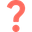
Проанализируйте и изложите содержательный смысл полученных
результатов.

## В первом эксперименте при увеличении длины временного ряда время работы наивного алгоритма росло примерно линейно. Это связано с увеличением количества подпоследовательностей, для которых необходимо вычислить DTW.
## Во втором эксперименте увеличение длины запроса приводило к более быстрому, нелинейному росту времени, особенно при широкой полосе Сако–Чиба. Более длинный запрос увеличивает размер матрицы DTW, а при фиксированном относительном r - и ширину допустимой полосы в ячейках.
## В обоих экспериментах уменьшение r ускоряло поиск за счет сокращения числа вычисляемых ячеек. Быстрее всего алгоритм работал при r = 0, когда вычисления выполнялись только по диагонали. Однако слишком узкая полоса ограничивает возможность сопоставлять участки со сдвигами во времени, поэтому выбирать ее только по скорости нельзя.

## **Часть 3.** Алгоритм UCR-DTW.

Третья часть практической работы посвящена алгоритму UCR-DTW, который использует нижние границы схожести $\text{LB}_{\text{Kim}}\text{FL}$, $\text{LB}_{\text{Keogh}}\text{EQ}$ и $\text{LB}_{\text{Keogh}}\text{EC}$, применяющиеся каскадным образом. Псевдокод алгоритма UCR-DTW представлен ниже.

<center><img src="https://github.com/mzym/TimeSeriesCourse/blob/main/practice/02%20Similarity%20search/img/ucr_dtw.png?raw=true" width="650"></center>

**Нижняя граница схожести (lower bound, LB)** представляет собой функцию, вычислительная сложность которой меньше вычислительной сложности меры DTW. Нижняя граница используется для отбрасывания кандидатов (подпоследовательностей временного ряда), заведомо не похожих на запрос, без вычисления меры DTW.

Нижние границы между кандидатом
$C$ и запросом $Q$ длины $n$, применяемые в UCR-DTW, вычисляются следующим образом:
<ul>
<li><b>Нижняя граница $\text{LB}_{\text{Kim}}\text{FL}$</b> определяется как сумма квадратов разностей между первыми и последними точками запроса $Q$ и
подпоследовательности $C$:
\begin{equation}
    \text{LB}_{\text{Kim}}\text{FL}(Q, C) = (q_1 - c_1)^2 + (q_n - c_n)^2.
\end{equation}
</li>

<li><b>Нижняя граница $\text{LB}_{\text{Keogh}}\text{EQ}$</b> показывает расстояние между верхней или нижней оболочкой $U$ и $L$, построенными вокруг запроса $Q$, и кандидатом $C$:
\begin{equation}
    \text{LB}_{\text{Keogh}}\text{EQ}(Q,C) = \sum_{i=1}^n{\left\{
            \begin{array}{cl}
            (c_i - u_i)^2, & \text{if} \; c_i > u_i \\
            (c_i - l_i)^2, & \text{if} \; c_i < l_i\\
            0, & \text{otherwise}.
            \end{array}
            \right.}
\end{equation}

Нижней и верхней оболочкой (lower and upper envelope) запроса $Q$ называют соответственно последовательности $L = (l_1,..., l_n)$ и $U = (u_1,..., u_n)$, вычисляемые как минимумы и максимумы запроса в скользящем окне заданной длины $r$ ($1 < r < m$):
\begin{equation}
    u_i = \max_{\max(1,i-r) \leqslant k \leqslant \min(m, i+r)} q_{k}, \\
    l_i = \min_{\max(1,i-r) \leqslant k \leqslant \min(m, i+r)} q_{k},
\end{equation}
где $r$ – ширина полосы Сако–Чиба.
</li>

<li><b>Нижняя граница $\text{LB}_{\text{Keogh}}\text{EC}$</b> представляет собой расстояние между запросом $Q$ и оболочкой кандидата $C$, т.е. является реверс-версией нижней границы $\text{LB}_{\text{Keogh}}\text{EQ}$:
\begin{equation}
    \text{LB}_{\text{Keogh}}\text{EC}(Q,C) = \text{LB}_{\text{Keogh}}\text{EQ}(C, Q).
\end{equation}
</li>
</ul>

### **Задача 7.**
  
Реализуйте технику каскадного применения нижних границ и сами нижние границы,  заполнив пропуски в классе `UCR_DTW`, в модуле *bestmatch.py*.
Выполните алгоритм UCR-DTW на данных ЭКГ из предыдущих частей, задав такие же значения входных параметров, что и для наивного алгоритма из части 2, и визуализируйте результаты. Убедитесь, что результаты UCR-DTW совпадают с результатами наивного алгоритма.

In [ ]:
import importlib
import modules.bestmatch as bestmatch
import modules.prediction as prediction

In [ ]:
top_k = 2
r = 0.01
excl_zone_frac = 0.5
is_normalize = True

ts = np.loadtxt('./datasets/part1/ECG.csv').reshape(-1)
query = np.loadtxt('./datasets/part1/ECG_query.csv').reshape(-1)

params = {
    'topK': top_k,
    'r': r,
    'excl_zone_frac': excl_zone_frac,
    'is_normalize': is_normalize
}

ucr_model = bestmatch.UCR_DTW(**params)
ucr_dtw_results = ucr_model.perform(ts, query)

naive_model = bestmatch.NaiveBestMatchFinder(**params)
naive_bestmatch_results = naive_model.perform(ts, query)

print("Результаты UCR-DTW:")

for idx, dist in zip(
    ucr_dtw_results['indices'],
    ucr_dtw_results['distances']
):
    print(f"Индекс: {idx}, расстояние DTW: {dist:.5f}")

np.testing.assert_array_equal(
    ucr_dtw_results['indices'],
    naive_bestmatch_results['indices']
)

np.testing.assert_allclose(
    ucr_dtw_results['distances'],
    naive_bestmatch_results['distances'],
    rtol=1e-10,
    atol=1e-10
)

print("\nРезультаты UCR-DTW и наивного алгоритма совпадают.")

plot_bestmatch_results(ts, query, ucr_dtw_results)

Результаты UCR-DTW:
Индекс: 1214, расстояние DTW: 13.92622
Индекс: 192, расстояние DTW: 192.95751

Результаты UCR-DTW и наивного алгоритма совпадают.


Визуализируйте количество неотброшенных и отброшенных каждой нижней границей подпоследовательностей временного ряда в виде круговой диаграммы с помощью функции `pie_chart()` из модуля *plots.py*.

In [ ]:
from modules.plots import pie_chart

statistics = ucr_model.get_statistics()

labels = np.array([
    'Не отброшены',
    'Отброшены LB_Kim',
    'Отброшены LB_Keogh оболочка запроса',
    'Отброшены LB_Keogh оболочка кандидата'
])

values = np.array([
    statistics['not_pruned_num'],
    statistics['lb_Kim_num'],
    statistics['lb_KeoghQC_num'],
    statistics['lb_KeoghCQ_num']
])

for label, value in zip(labels, values):
    print(f"{label}: {value}")

pie_chart(
    labels=labels,
    values=values,
    plot_title='Результаты каскадных проверок UCR-DTW'
)

Не отброшены: 59
Отброшены LB_Kim: 50
Отброшены LB_Keogh оболочка запроса: 4628
Отброшены LB_Keogh оболочка кандидата: 0


### **Задача 8.**

Проведите эксперименты, аналогичные тем, которые выполнялись для исследования эффективности наивного алгоритма в задаче 6. Постройте графики и вычислите ускорение алгоритма UCR-DTW относительно наивного алгоритма. Для справедливого сравнения алгоритмов используйте сгенерированные временные ряды и запросы из задачи 6.

Эксперимент 1

In [ ]:
import importlib
import numpy as np
import modules.bestmatch as bestmatch
import modules.experiments as experiments

In [ ]:
algorithm = 'ucr-dtw'
algorithm_params = {
    'topK': 3,
    'excl_zone_frac': 1,
    'is_normalize': True,
}

n_list = [2**10, 2**11, 2**12, 2**13, 2**14, 2**15] # lengths of time series
r_list = np.round(np.arange(0, 0.6, 0.1), 2).tolist() # sizes of warping window
m = 2**6 # length of query

exp1_params = {
    'varying': {'n': n_list,
                'r': r_list},
    'fixed': {'m': m}
}
exp1_data = {
    'ts': dict.fromkeys(map(str, n_list), []),
    'query': {str(m): []}
}

task = 'best_match'

# generate set of time series and query
# run experiments for measurement of algorithm runtimes

# INSERT YOUR CODE

exp1_data = naive_exp1_data

ucr_exp1_times = []

for r_value in r_list:
    print(f"Начат расчет для r = {r_value}", flush=True)

    current_params = {
        'varying': {
            'n': n_list,
            'r': [r_value]
        },
        'fixed': {'m': m}
    }

    times = experiments.run_experiment(
        algorithm=algorithm,
        task=task,
        data=exp1_data,
        exp_params=current_params,
        alg_params=algorithm_params
    )

    if not np.all(np.isfinite(times)) or np.any(times <= 0):
        raise RuntimeError(
            f"При r = {r_value} получено некорректное время."
        )

    ucr_exp1_times.append(times[0])

    print(
        f"Завершено: {np.round(times[0], 3)} секунд",
        flush=True
    )

ucr_exp1_times = np.array(ucr_exp1_times)

ucr_exp1_data = exp1_data
ucr_exp1_params = exp1_params

print("Размер массива:", ucr_exp1_times.shape)

Начат расчет для r = 0.0
Завершено: [0.095 0.217 0.302 0.668 1.201 2.947] секунд
Начат расчет для r = 0.1
Завершено: [0.238 0.532 0.506 0.747 1.921 4.659] секунд
Начат расчет для r = 0.2
Завершено: [0.483 1.077 1.151 1.821 3.569 9.598] секунд
Начат расчет для r = 0.3
Завершено: [ 0.947  1.672  1.718  3.475  8.439 14.999] секунд
Начат расчет для r = 0.4
Завершено: [ 1.445  2.066  2.34   6.379  7.772 18.31 ] секунд
Начат расчет для r = 0.5
Завершено: [ 3.851  2.753  2.82   4.789 15.14  24.831] секунд
Размер массива: (6, 6)


In [ ]:
#visualize plot with results of experiment
comparison_param = np.array(r_list)

# INSERT YOUR CODE
experiments.visualize_plot_times(
    ucr_exp1_times,
    comparison_param,
    ucr_exp1_params
)

In [ ]:
# visualize table with speedup
tab_index = [f"n = {n}" for n in n_list]
tab_columns = [f"r = {r}" for r in r_list]
tab_title = "Speedup UCR-DTW relative to the naive algorithm <br> (variable time series length and warping path size, fixed query length)"

# INSERT YOUR CODE

speedup_exp1 = experiments.calculate_speedup(
    np.asarray(naive_exp1_times),
    ucr_exp1_times
)

experiments.visualize_table_speedup(
    speedup_data=speedup_exp1.T,
    table_index=tab_index,
    table_columns=tab_columns,
    table_caption=tab_title
)

,r = 0.0,r = 0.1,r = 0.2,r = 0.3,r = 0.4,r = 0.5
n = 1024,1.682664,7.109951,4.376702,2.436043,1.964999,1.329123
n = 2048,1.198458,5.033130,4.628234,3.894686,2.791685,2.705489
n = 4096,1.652562,7.458014,5.579880,5.638835,6.356059,6.006342
n = 8192,1.513315,12.849823,8.418840,6.707611,5.381632,7.221030
n = 16384,1.733758,9.477928,9.994701,5.278212,7.861244,4.748070
n = 32768,1.616809,7.455870,6.585452,6.650164,6.895609,5.538004


Эксперимент 2

In [ ]:
m_list = [2**4, 2**5, 2**6, 2**7, 2**8] # lengths of query
r_list = np.round(np.arange(0, 0.6, 0.1), 2).tolist() # sizes of warping window
n = 2**12 # length of time series

exp_params = {
    'varying': {'m': m_list,
                'r': r_list},
    'fixed': {'n': n}
}
data = {
    'ts': {str(n): []},
    'query': dict.fromkeys(map(str, m_list), []),
}

# INSERT YOUR CODE

data = naive_exp2_data

algorithm = 'ucr-dtw'
task = 'best_match'

algorithm_params = {
    'topK': 3,
    'excl_zone_frac': 1,
    'is_normalize': True
}

ucr_exp2_times = []

for r_value in r_list:
    print(f"Начат расчет для r = {r_value}", flush=True)

    current_params = {
        'varying': {
            'm': m_list,
            'r': [r_value]
        },
        'fixed': {'n': n}
    }

    times = experiments.run_experiment(
        algorithm=algorithm,
        task=task,
        data=data,
        exp_params=current_params,
        alg_params=algorithm_params
    )

    if not np.all(np.isfinite(times)) or np.any(times <= 0):
        raise RuntimeError(
            f"При r = {r_value} получено некорректное время."
        )

    ucr_exp2_times.append(times[0])

    print(
        f"Завершено: {np.round(times[0], 3)} секунд",
        flush=True
    )

ucr_exp2_times = np.array(ucr_exp2_times)

ucr_exp2_data = data
ucr_exp2_params = exp_params

print("Размер массива:", ucr_exp2_times.shape)

Начат расчет для r = 0.0
Завершено: [0.228 0.458 0.46  0.438 0.514] секунд
Начат расчет для r = 0.1
Завершено: [0.194 0.412 2.211 2.405 7.577] секунд
Начат расчет для r = 0.2
Завершено: [ 0.226  0.589  1.616  4.548 24.148] секунд
Начат расчет для r = 0.3
Завершено: [ 0.259  0.902  5.71   8.31  49.557] секунд
Начат расчет для r = 0.4
Завершено: [ 0.331  2.138  7.242 13.451 74.028] секунд
Начат расчет для r = 0.5
Завершено: [  0.388   1.682   9.698  17.531 111.719] секунд
Размер массива: (6, 5)


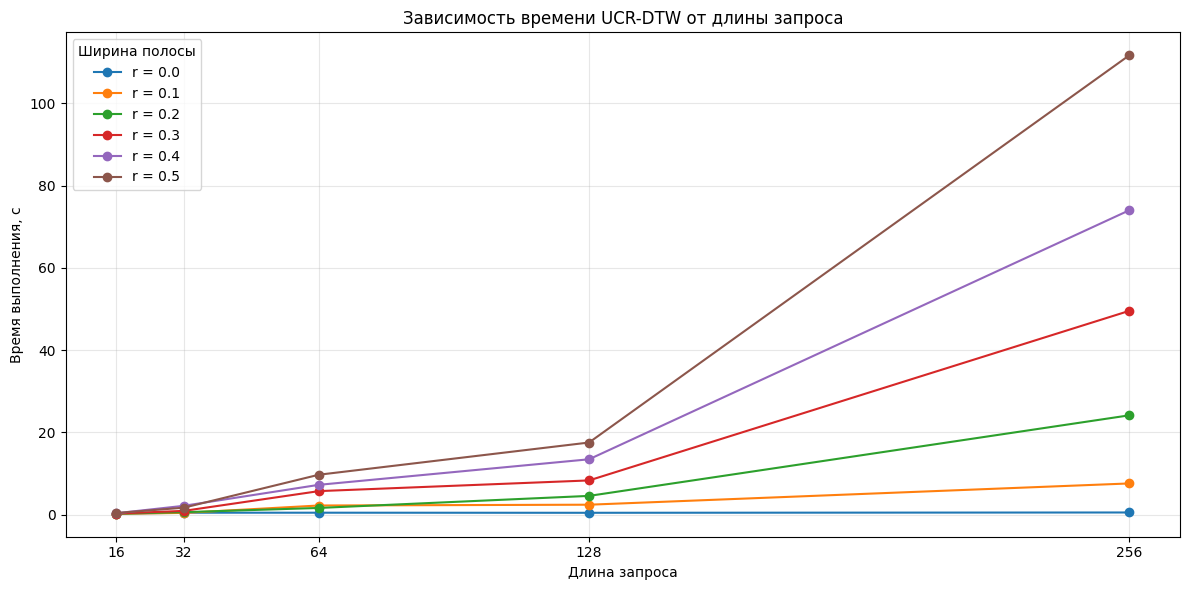

In [ ]:
comparison_param = np.array(r_list)
plt.figure(figsize=(12, 6))

for i, r_value in enumerate(comparison_param):
    plt.plot(
        ucr_exp2_params['varying']['m'],
        ucr_exp2_times[i],
        marker='o',
        label=f'r = {r_value}'
    )

plt.title('Зависимость времени UCR-DTW от длины запроса')
plt.xlabel('Длина запроса')
plt.ylabel('Время выполнения, с')
plt.xticks(ucr_exp2_params['varying']['m'])
plt.legend(title='Ширина полосы')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
tab_index = [f"m = {m}" for m in m_list]
tab_columns = [f"r = {r}" for r in r_list]
tab_title = "Speedup UCR-DTW relative to the naive algorithm <br> (variable query length and warping path size, fixed time series length)"

# INSERT YOUR CODE

speedup_exp2 = experiments.calculate_speedup(
    np.asarray(naive_exp2_times),
    ucr_exp2_times
)

experiments.visualize_table_speedup(
    speedup_data=speedup_exp2.T,
    table_index=tab_index,
    table_columns=tab_columns,
    table_caption=tab_title
)

,r = 0.0,r = 0.1,r = 0.2,r = 0.3,r = 0.4,r = 0.5
m = 16,0.991034,2.266905,2.825444,3.076661,5.553014,2.990352
m = 32,0.836325,3.030632,3.826164,2.801545,2.017065,2.369074
m = 64,1.231052,2.404640,5.766300,2.091906,1.937020,1.714235
m = 128,2.238878,7.289910,6.962821,5.296100,3.989468,3.834266
m = 256,3.360872,8.469835,5.004744,3.331771,2.866421,2.229703


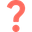
Проанализируйте и изложите содержательный смысл полученных
результатов.

UCR-DTW оказался быстрее наивного алгоритма во всех случаях первого эксперимента и в большинстве случаев второго. Максимальное ускорение составило 12,85 в первом эксперименте и 8,47 во втором.

С увеличением длины ряда, запроса и ширины полосы время в целом росло. При коротких запросах и r = 0 ускорения не было, затраты на проверки нижних границ могли превышать экономию вычислений. Поэтому выигрыш UCR-DTW зависит от данных и параметров поиска.

### **Задача 9.**

В данном задании вам предстоит определелить, какую функцию расстояния ED или DTW лучше всего использовать на практике для поиска наиболее похожих подпоследовательностей временного ряда на запрос. Чтобы это сделать, рассмотрим две задачи из различных предметных областей, решить которые предлагается с помощью алгоритмов поиска по образцу.

Начнем с **первой задачи из области физиологии человека**. На человеке сначала закрепляют множество акселерометров и гироскопов, после чего он выполняет в помещении последовательность заранее определенных действий (активностей) в течение некоторого промежутка времени. Примерами таких активностей являются открывание/закрывание дверей, включение/выключение света, питье из чашки стоя/сидя и др. В то время как человек выполняет эти активности, датчики фиксируют его скорость и направление наклона тела. Задача дата-сайентиста заключается в том, что необходимо распознать в снятых данных все активности, которые выполнял человек.  

Данную задачу упростим, и будем выполнять поиск только одной активности во временном ряде при условии, что у нас имеется образец этой активности. В качестве данных возьмем временной ряд показаний гироскопа, закрепленного на правом запятье руки человека, из набора данных [Opportunity](https://archive.ics.uci.edu/dataset/226/opportunity+activity+recognition) и образец искомой активности, питья из чашки стоя. Данный ряд соответствует примерно 14-минутной записи.

Загрузите временной ряд и образец поиска из директории `./datasets/part3/Opportunity` в ноутбук.    

In [ ]:
# INSERT YOUR CODE
import numpy as np

ts = np.loadtxt('./datasets/part3/Opportunity/ts.csv').reshape(-1)
query = np.loadtxt('./datasets/part3/Opportunity/query.csv').reshape(-1)

print("Длина временного ряда:", len(ts))
print("Длина запроса:", len(query))

Длина временного ряда: 17285
Длина запроса: 300


Выполните поиск похожих подпоследовательностей на запрос с помощью реализованных вами ранее алгоритмов MASS и UCR-DTW. Согласно истинной разметке, искомую активность человек выполнял 7 раз, поэтому параметр $topK=7$.

In [ ]:
topK = 7
r = 0.1
excl_zone_frac = 1
is_normalize = True

# INSERT YOUR CODE

mass_profile = np.real(mts.mass2(ts, query))

excl_zone = int(np.ceil(len(query) * excl_zone_frac))

mass_results = bestmatch.topK_match(
    mass_profile,
    excl_zone=excl_zone,
    topK=topK
)

ucr_model = bestmatch.UCR_DTW(
    topK=topK,
    r=r,
    excl_zone_frac=excl_zone_frac,
    is_normalize=is_normalize
)

ucr_dtw_results = ucr_model.perform(ts, query)

print("MASS:")
print("Количество найденных участков:", len(mass_results['indices']))
print("Индексы начала:", mass_results['indices'])

print("\nUCR-DTW:")
print("Количество найденных участков:", len(ucr_dtw_results['indices']))
print("Индексы начала:", ucr_dtw_results['indices'])

MASS:
Количество найденных участков: 7
Индексы начала: [np.int64(16663), np.int64(6664), np.int64(4245), np.int64(11788), np.int64(1907), np.int64(14270), np.int64(16102)]

UCR-DTW:
Количество найденных участков: 7
Индексы начала: [11799, 1916, 16663, 9291, 6650, 14264, 4248]


Чтобы оценить качество распознавания активности, загрузите имеющуюся истинную разметку, хранящуюся в файле *labels.csv*. В разметке значением 1 обозначаются моменты времени, когда человек пил из чашки стоя, и значением 0 – в противном случае. Вычислите среди найденных $topK$ подпоследовательностей количество TP (True Positive) и FN (False Negative) с помощью функции `calculate_task1_accuracy()` и сравните между собой показатели, полученные с помощью MASS и UCR-DTW.

In [ ]:
def calculate_task1_accuracy(labels: np.array, predicted_results: np.array) -> dict:
    """
    Calculate the accuracy of the algorithm which performs the activity recognition

    Parameters
    ----------
    labels: true labels
    predicted_results: results are predicted by algorithm

    Returns
    -------
        The number of True Positive and False Negative examples
    """

    TP = 0
    FN = 0

    topK = len(predicted_results['indices'])

    for i in range(topK):
        idx = predicted_results['indices'][i]
        if (labels[idx] == 1):
            TP = TP + 1

    FN = topK - TP

    return {'TP': TP,
            'FN': FN}

In [ ]:
# INSERT YOUR CODE

import numpy as np
import pandas as pd

labels = np.loadtxt(
    './datasets/part3/Opportunity/labels.csv',
    dtype=int
).reshape(-1)

mass_accuracy = calculate_task1_accuracy(labels, mass_results)
ucr_accuracy = calculate_task1_accuracy(labels, ucr_dtw_results)

comparison = pd.DataFrame(
    [mass_accuracy, ucr_accuracy],
    index=['MASS', 'UCR-DTW']
)

display(comparison)

if mass_accuracy['TP'] > ucr_accuracy['TP']:
    print("По данной проверке больше правильных совпадений у MASS.")
elif mass_accuracy['TP'] < ucr_accuracy['TP']:
    print("По данной проверке больше правильных совпадений у UCR-DTW.")
else:
    print("Количество правильных совпадений у алгоритмов одинаковое")

,TP,FN
MASS,6,1
UCR-DTW,7,0


По данной проверке больше правильных совпадений у UCR-DTW.


Итоговый вывод о преимуществе одной функции расстояния над другой в задаче поиска по образцу на данный момент делать еще рано, поэтому решим **вторую задачу из области транспорта**. Данная задача заключается в прогнозировании потока пешеходов в некоторой точке города на основе прошлых данных.

Прогнозирование ряда $T$ длины $n$ будем выполнять следующим образом. Сначала сформируем запрос $Q$, состоящий из $m$ последних по времени элементов ряда, $Q = T_{n-m+1,m}$. Далее среди всех подпоследовательностей ряда $T$, начинающихся с 1 до $n-2m$ позиций, найдем $topK$ похожих на запрос $Q$. Обозначим за $h > 0$ горизонт прогнозирования, определяющий количество элементов ряда, значения которых необходимо спрогнозировать. Для нахождения будущих значений будем брать $h$ элементов ряда, которые следуют за концевыми точками найденных похожих подпоследовательностей. В итоге, будущие значения будут получаться путем применения агрегатной функции к этим элементам. В качестве агрегатной функции может использоваться среднее арифметическое, взвешенное среднее, медиана и др.

Загрузите временной ряд из файла *pedestrian_count.csv*, расположенного в директории *./datasets/part3/Melbourne*. Данный ряд содержит почасовую статистику о количестве пешеходов на улице Бурке в Мельбурне (Австралия), являющейся одной из главных улиц города. Данные собраны за период с 1 марта 2020 по 31 октября 2022 гг. Полный набор данных и его детальное описание доступны по следующей [ссылке](https://data.melbourne.vic.gov.au/explore/dataset/pedestrian-counting-system-monthly-counts-per-hour/information/).

In [ ]:
data_path = './datasets/part3/Melbourne/pedestrian_count.csv'

data = pd.read_csv(data_path, header=0)

Реализуйте алгоритм прогнозирования временного ряда на основе UCR-DTW и MASS, следуя приведенному выше описанию. За прогнозирование отвечает класс `BestMatchPredictor` из модуля *prediction.py*, дополните его недостающим кодом.  

Далее выполните прогнозирование потока людей для исходных данных на 1 день вперед (24 значения). Для этого установите следующие входные параметры:
<ul>
  <li>$h = 24$ (горизонт прогнозирования);</li>
  <li>$m = 168$ (длина запроса и подпоследовательностей, соответствующая 1 неделе);</li>
  <li>$aggr\_func = \text{'average'}$ (агрегатная функция);</li>
  <li>для алгоритма UCR-DTW:
    <ul>
      <li>$topK = 5$ (количество похожих подпоследовательностей на запрос);</li>
      <li>$r = 0.1$ (ширина полосы Сако–Чиба);</li>
      <li>$excl\_zone\_frac = 1$ (доля от длины подпоследовательностей, на основе которой определяется, являются ли подпоследоватлеьности тривиальными совпадениями);</li>
      <li>$is\_normalize = True$ ($z$-нормализация запроса и подпоследовательностей);</li>
    </ul>
  </li>
  <li>для алгоритма MASS:</li>
    <ul>
      <li>$topK = 5$ (количество похожих подпоследовательностей на запрос);</li>
      <li>$excl\_zone\_frac = 1$ (доля от длины подпоследовательностей, на основе которой определяется, являются ли подпоследоватлеьности тривиальными совпадениями).</li>
    </ul>
</ul>

Будем считать, что последние $h$ значений в загруженном временном ряде $T$ длины $n$ отсутствуют. Поэтому перед тем как находить прогнозные значения,  подготовьте данные. Разделите загруженный временной ряд $T$ на три части:
<ol>
  <li>ряд $T_{train}$, в котором будет выполняться поиск похожих подпоследовательностей на запрос $Q$: $T_{train} = T[0:(n-m-h)]$</li>
  <li>запрос $Q$: $Q = T[(n-m-h) : (n-h)]$</li>
  <li>реальные значения ряда $real\_values$, которые необходимо спрогнозировать: $real\_values = T[-h:] $</li>
</ol>

In [ ]:
importlib.reload(prediction)

ucr_dtw_params = {
    'topK': 5,
    'r': 0.1,
    'excl_zone_frac': 1,
    'is_normalize': True
}

h = 24
m = 168
aggr_func = 'average'

data = pd.read_csv(
    './datasets/part3/Melbourne/pedestrian_count.csv'
)

T = data['Hourly_Counts'].to_numpy(dtype=float)
n = len(T)

T_train = T[:n - m - h]
Q = T[n - m - h:n - h]
real_values = T[-h:]

print("Длина ряда для поиска:", len(T_train))
print("Длина запроса:", len(Q))
print("Горизонт прогнозирования:", h)

ucr_predictor = prediction.BestMatchPredictor(
    h=h,
    match_alg='UCR-DTW',
    match_alg_params=ucr_dtw_params,
    aggr_func=aggr_func
)

ucr_predict_values = ucr_predictor.predict(T_train, Q)

print("\nПрогноз UCR-DTW:")
print(ucr_predict_values)

Длина ряда для поиска: 22117
Длина запроса: 168
Горизонт прогнозирования: 24

Прогноз UCR-DTW:
[ 11.  16.  43.  87. 126. 146. 215. 337. 472. 460. 487. 576. 742. 730.
 592. 533. 482. 449. 376. 251. 136.  48.  43.  17.]


In [ ]:
mass_params = {
    'topK': 5,
    'excl_zone_frac': 1
}

mass_predictor = prediction.BestMatchPredictor(
    h=h,
    match_alg='MASS',
    match_alg_params=mass_params,
    aggr_func=aggr_func
)

mass_predict_values = mass_predictor.predict(T_train, Q)

print("Прогноз MASS:")
print(mass_predict_values)

Прогноз MASS:
[ 23.  11.  12.   4.   4.   6.  48. 131. 251. 295. 362. 455. 775. 760.
 550. 537. 489. 571. 437. 294. 205. 168. 100.  74.]


Далее выполните сравнение эффективности алгоритма при UCR-DTW и MASS по точности прогнозирования. Для оценки точности используйте **меру
среднеквадратичной ошибки RMSE (Root Mean Square Error)**, которая определяется следующим образом:
\begin{equation}
RMSE = \sqrt{\frac{1}{h}\sum_{i=1}^h{(t_i-\tilde{t}_i)}^2},
\end{equation}
где $t_i$ и $\tilde{t}_i$ — фактическое и прогнозное значения элемента ряда, $h$ — количество прогнозных элементов временного ряда.

In [ ]:
from sklearn.metrics import mean_squared_error

rmse_ucr = np.sqrt(
    mean_squared_error(real_values, ucr_predict_values)
)

rmse_mass = np.sqrt(
    mean_squared_error(real_values, mass_predict_values)
)

print(f"RMSE UCR-DTW: {rmse_ucr:.4f}")
print(f"RMSE MASS: {rmse_mass:.4f}")

if rmse_ucr < rmse_mass:
    print("Меньшая ошибка прогноза у UCR-DTW")
elif rmse_mass < rmse_ucr:
    print("Меньшая ошибка прогноза у MASS")
else:
    print("Ошибки прогноза одинаковые")

RMSE UCR-DTW: 161.0036
RMSE MASS: 149.2460
Меньшая ошибка прогноза у MASS


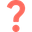 Сделайте вывод о влиянии функции расстояния ED и DTW на точность решения задач интеллектульного анализа данных, которые основаны на алгоритмах поиска по образцу.  

Лучший результат показал UCR-DTW, по проверке разметки правильными оказались 7 найденных участков, у MASS только 6. DTW допускает локальные смещения при сравнении последовательностей, что может быть полезно при разной скорости выполнения движений.

В прогнозировании потока пешеходов точнее оказался MASS с евклидовым расстоянием - RMSE составила 149.25, а у UCR-DTW 161.

Таким образом, DTW не гарантирует более высокую точность во всех задачах. Выбор между ED и DTW зависит от особенностей данных.